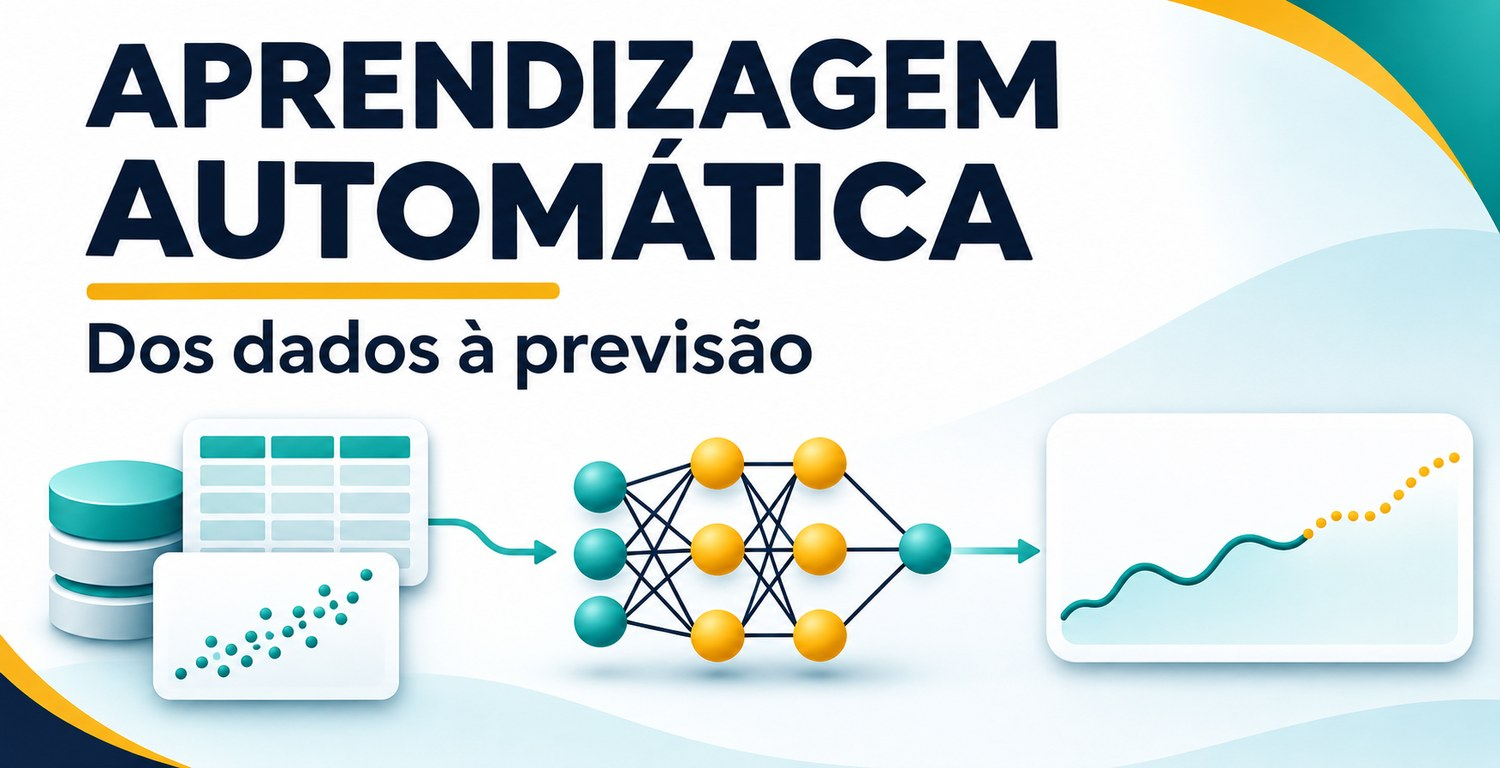

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Aprendizagem%20Autom%C3%A1tica/tutorial_machine_learning/modulo_1_aprender_com_dados/01_Relembrar_o_Essencial.ipynb)

# Capítulo 1 – Relembrar: o essencial antes de começar

Este tutorial parte de ideias que já foram tratadas a fundo no tutorial [Introdução à Ciência de Dados](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados): o que é um modelo, porque se separa um conjunto de teste, como se prepara sem fugas de informação, como se avalia um classificador e o que é o sobreajuste. Este capítulo relembra essas ideias em cinco partes. Cada parte tem um resumo, um exemplo que podes executar, um ou dois exercícios de reforço com uma solução possível e a ligação para o capítulo onde o assunto é explicado de raiz.

Se uma parte for nova para ti, segue a ligação antes de continuares. Se resolveres os exercícios sem dificuldade, estás pronto para o resto do tutorial.

> **Objetivos:** rever o vocabulário (atributos, alvo, treinar, prever); rever a divisão em treino e teste e a linha de base; rever a regra «o que aprende com os dados ajusta-se só no treino» e o *pipeline*; rever a matriz de confusão, a precisão, a sensibilidade e o limiar; rever o sobreajuste e a validação cruzada.

**Pré-requisitos:** Python, NumPy e pandas ao nível do tutorial [Introdução ao Python](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python). A revisão dessas ferramentas está em [Revisão de Python, NumPy e pandas](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_3_explorar_os_dados/01_Revisao_Python_NumPy_Pandas.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O caso deste módulo: os lotes de um lagar

Um lagar cooperativo recebe, em cada campanha, centenas de lotes de azeitona de três variedades. À chegada de cada lote, mede uma amostra de frutos e regista o índice de maturação e a humidade. Depois da extração, fica a saber o **rendimento**: os quilos de azeite obtidos por cada 100 kg de azeitona.

O lagar tem várias perguntas a que um modelo pode ajudar a responder, e vamos usá-las ao longo do módulo. Os dados são sintéticos: os nomes das variedades existem, mas as medições foram inventadas para este tutorial.

In [2]:
def gerar_lotes(n=900, semente=7):
    """Gera lotes de azeitona entregues num lagar fictício (dados sintéticos; as medições são inventadas)."""
    rng = np.random.default_rng(semente)
    # variedade: peso médio do fruto (g), comprimento (mm), razão comprimento/largura, rendimento de base (%)
    perfis = {"Galega": (2.4, 17.5, 1.42, 15.5), "Cobrançosa": (4.3, 22.0, 1.33, 18.5), "Cordovil": (5.0, 23.0, 1.22, 20.0)}
    variedade = rng.choice(list(perfis), n, p=[0.45, 0.33, 0.22])
    base = np.array([perfis[v] for v in variedade])
    peso = np.clip(rng.normal(base[:, 0], 0.55), 1.0, None)
    comprimento = base[:, 1] + 2.2 * (peso - base[:, 0]) + rng.normal(0, 1.1, n)
    largura = comprimento / base[:, 2] + rng.normal(0, 0.5, n)
    maturacao = np.clip(rng.normal(3.4, 1.2, n), 0, 7)
    humidade = np.clip(rng.normal(52 - 1.5 * (maturacao - 3.4), 4), 38, 66)
    rendimento = base[:, 3] + 1.1 * (maturacao - 3.4) - 0.28 * (humidade - 52) + rng.normal(0, 1.0, n)
    return pd.DataFrame({
        "lote_id": [f"L{i:04d}" for i in range(1, n + 1)],
        "variedade": variedade,
        "peso_g": peso.round(2),
        "comprimento_mm": comprimento.round(1),
        "largura_mm": largura.round(1),
        "maturacao": maturacao.round(1),
        "humidade_pct": humidade.round(1),
        "rendimento_pct": rendimento.round(1),
    })


lotes = gerar_lotes()
print(lotes.shape)
lotes.head()

(900, 8)


,lote_id,variedade,peso_g,comprimento_mm,largura_mm,maturacao,humidade_pct,rendimento_pct
0,L0001,Cobrançosa,4.24,21.3,15.7,3.1,53.2,17.9
1,L0002,Cordovil,5.25,22.5,18.3,6.3,48.3,25.7
2,L0003,Cobrançosa,4.71,23.9,17.5,3.0,52.5,18.3
3,L0004,Galega,2.16,15.8,10.4,2.0,57.2,11.5
4,L0005,Galega,2.57,15.5,10.2,3.4,44.4,17.0


| Coluna | Significado | Tipo |
| --- | --- | --- |
| `lote_id` | Identificador do lote | identificador |
| `variedade` | Galega, Cobrançosa ou Cordovil | nominal |
| `peso_g` | Peso médio de um fruto, em gramas | contínua |
| `comprimento_mm` | Comprimento médio de um fruto | contínua |
| `largura_mm` | Largura média de um fruto | contínua |
| `maturacao` | Índice de maturação, de 0 (verde) a 7 (muito madura) | contínua |
| `humidade_pct` | Humidade da pasta, em percentagem | contínua |
| `rendimento_pct` | Quilos de azeite por 100 kg de azeitona, conhecido só depois da extração | contínua |

## Parte 1 – Atributos, alvo, treinar e prever

Em resumo:

- Na programação tradicional, uma pessoa escreve as regras. Na aprendizagem automática, o computador recebe exemplos com a resposta e **ajusta** as regras: o resultado é um **modelo**.
- Um programa aprende se o seu desempenho **P** numa tarefa **T** melhora com a experiência **E** (definição de Mitchell).
- Os **atributos** são as colunas que se conhecem no momento de prever e guardam-se numa tabela `X`, com uma linha por exemplo. O **alvo** é a coluna que se quer prever e guarda-se num vetor `y`.
- **Treinar** (`fit`) é ajustar os parâmetros do modelo aos exemplos. **Prever** (`predict`) é aplicar o modelo a casos novos.
- Se o alvo é um número, o problema é de **regressão**. Se é uma categoria, é de **classificação**.

In [3]:
from sklearn.linear_model import LinearRegression

atributos = ["maturacao", "humidade_pct"]
X = lotes[atributos]                 # tabela de atributos: uma linha por lote
y = lotes["rendimento_pct"]          # alvo: um valor por lote
print("X:", X.shape, "| y:", y.shape)

modelo = LinearRegression().fit(X, y)                    # treinar
print("Parâmetros aprendidos:", {a: round(float(c), 2) for a, c in zip(atributos, modelo.coef_)}, "| ordenada:", round(float(modelo.intercept_), 2))

lote_novo = pd.DataFrame({"maturacao": [4.5], "humidade_pct": [49.0]})
print("Rendimento previsto para o lote novo:", modelo.predict(lote_novo).round(1), "%")     # prever

X: (900, 2) | y: (900,)
Parâmetros aprendidos: {'maturacao': 1.14, 'humidade_pct': -0.26} | ordenada: 27.24
Rendimento previsto para o lote novo: [19.5] %


O modelo aprendeu dois coeficientes e uma ordenada. O sinal de cada coeficiente lê-se diretamente: azeitona mais madura dá mais azeite, e pasta mais húmida dá menos.

**Para rever a fundo:** [O que é aprender com dados](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/01_O_que_e_Aprender_com_Dados.ipynb) · [Scikit-Learn: fundamentos](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_03_ScikitLearn_Fundamentos.ipynb)

### `Exercício 1` – Que problema é este?

Para cada pergunta do lagar, indica a tarefa, a experiência, uma medida de desempenho, os atributos, o alvo e o tipo de problema.

1. À chegada de um lote, estimar o rendimento que ele vai dar.
2. Confirmar a variedade declarada pelo produtor, a partir das medições dos frutos.
3. Agrupar os produtores por perfil de entrega, sem categorias definidas à partida.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. T: prever o rendimento de um lote; E: os lotes de campanhas anteriores, com o rendimento que deram; P: o erro absoluto médio, em pontos percentuais. Atributos: as medições feitas à chegada. Alvo: `rendimento_pct`. É **regressão**.
2. T: atribuir uma variedade a um lote; E: lotes com a variedade confirmada; P: a proporção de lotes bem classificados. Atributos: peso, comprimento e largura. Alvo: `variedade`. É **classificação**.
3. T: formar grupos de produtores parecidos; E: os registos de entregas; não existe uma resposta certa com que comparar, por isso o desempenho mede-se pela utilidade dos grupos. Não há alvo: é aprendizagem **não supervisionada**.

No ponto 1, o rendimento não pode ser atributo: só se conhece depois da extração. Usar uma coluna que não existe no momento de prever é uma fuga de informação (parte 3).

</details>

### `Exercício 2` – Mais um atributo

Treina uma regressão linear para o rendimento com três atributos: `maturacao`, `humidade_pct` e `peso_g`. Calcula o erro absoluto médio deste modelo e o do modelo com dois atributos, nos mesmos lotes com que treinaste. O erro desceu?

In [4]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for colunas in [["maturacao", "humidade_pct"], ["maturacao", "humidade_pct", "peso_g"]]:
    m = LinearRegression().fit(lotes[colunas], y)
    erro = (m.predict(lotes[colunas]) - y).abs().mean()
    print(f"{len(colunas)} atributos: erro absoluto médio de {erro:.2f} pontos percentuais")
```

O erro desce bastante, porque o peso do fruto distingue as variedades, e as variedades têm rendimentos diferentes. Repara, porém, que estes erros foram medidos nos lotes de treino. Num modelo linear, acrescentar um atributo nunca faz subir o erro de treino, mesmo que o atributo seja ruído. Para saber se o modelo melhorou de facto, é preciso medi-lo em lotes que ele não viu.

</details>

## Parte 2 – Treino, teste e linha de base

Em resumo:

- O erro medido nos dados de treino é **otimista**. Um modelo flexível consegue decorar os exemplos e ter erro zero no treino sem ter aprendido nada de útil.
- Por isso separa-se um **conjunto de teste** antes de qualquer outra coisa. O modelo treina-se no treino e avalia-se no teste.
- O teste usa-se **uma vez**, no fim. Para comparar modelos e escolher hiperparâmetros usa-se um conjunto de validação ou a validação cruzada (parte 5).
- Um resultado só tem significado ao lado de uma **linha de base**: a previsão mais simples possível, como a média do treino (regressão) ou a classe mais frequente (classificação).

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

frutos = ["peso_g", "comprimento_mm", "largura_mm"]                 # medições dos frutos
medicoes = frutos + ["maturacao", "humidade_pct"]                   # tudo o que se mede à chegada
X_treino, X_teste, y_treino, y_teste = train_test_split(lotes[medicoes], lotes["rendimento_pct"], test_size=0.25, random_state=42)
print("Treino:", X_treino.shape, "| teste:", X_teste.shape)

candidatos = {"Linha de base (média do treino)": DummyRegressor(strategy="mean"),
              "Regressão linear": LinearRegression(),
              "Árvore sem limite de profundidade": DecisionTreeRegressor(random_state=0)}
linhas = []
for nome, m in candidatos.items():
    m.fit(X_treino, y_treino)
    linhas.append({"modelo": nome,
                   "erro no treino": mean_absolute_error(y_treino, m.predict(X_treino)),
                   "erro no teste": mean_absolute_error(y_teste, m.predict(X_teste))})
erros = pd.DataFrame(linhas).set_index("modelo").round(2)
erros

Treino: (675, 5) | teste: (225, 5)


,erro no treino,erro no teste
modelo,,
Linha de base (média do treino),2.42,2.42
Regressão linear,0.95,1.00
Árvore sem limite de profundidade,0.00,1.36


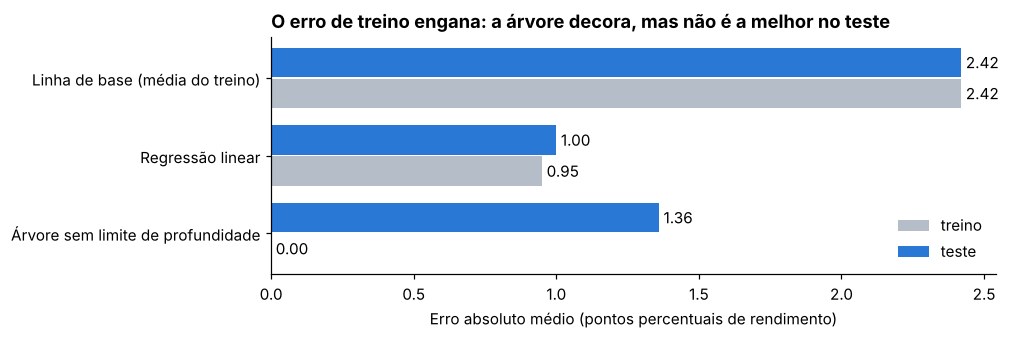

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 2.8))
posicoes = np.arange(len(erros))
b1 = ax.barh(posicoes + 0.2, erros["erro no treino"], height=0.38, color=CINZA, label="treino")
b2 = ax.barh(posicoes - 0.2, erros["erro no teste"], height=0.38, color=AZUL, label="teste")
ax.bar_label(b1, fmt="%.2f", padding=3)
ax.bar_label(b2, fmt="%.2f", padding=3)
ax.set_yticks(posicoes, erros.index)
ax.invert_yaxis()
ax.set_xlabel("Erro absoluto médio (pontos percentuais de rendimento)")
ax.set_title("O erro de treino engana: a árvore decora, mas não é a melhor no teste")
ax.legend(frameon=False, loc="lower right")
plt.show()

A árvore sem limite tem erro zero no treino: decorou os lotes. No teste, erra mais do que a regressão linear. A linha de base dá a escala: errar tanto como a média é não ter aprendido nada.

**Para rever a fundo:** [Treino, teste e linha de base](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/02_Treino_Teste_e_Linha_de_Base.ipynb)

### `Exercício 3` – Uma linha de base para a variedade

O lagar quer confirmar a variedade de cada lote a partir das medições dos frutos (a lista `frutos`).

1. Divide os dados em treino e teste (25% para teste), com `stratify` para manter as proporções das variedades.
2. Calcula a exatidão de uma linha de base que responde sempre a variedade mais frequente (`DummyClassifier`).
3. Treina um `KNeighborsClassifier` e compara.

In [7]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier

Xa, Xb, ya, yb = train_test_split(lotes[frutos], lotes["variedade"], test_size=0.25, random_state=42, stratify=lotes["variedade"])

base = DummyClassifier(strategy="most_frequent").fit(Xa, ya)
knn = KNeighborsClassifier(n_neighbors=5).fit(Xa, ya)
print(f"Linha de base: {base.score(Xb, yb):.2f} | KNN: {knn.score(Xb, yb):.2f}")
```

A linha de base acerta em cerca de 46% dos lotes, que é a proporção da Galega. O KNN fica muito acima. Sem a linha de base, uma exatidão de 46% podia parecer melhor do que o acaso entre três classes (33%), quando na verdade não usa informação nenhuma. O KNN foi treinado sem normalizar os atributos: a parte 3 trata disso.

</details>

## Parte 3 – Preparar sem fugas de informação

Em resumo:

- Uma **fuga de informação** acontece quando o modelo recebe, durante o treino, informação que não teria no momento de prever. O sintoma é um resultado excelente na validação que desaparece em produção.
- Há dois tipos. No primeiro, um atributo só existe depois de se conhecer o alvo. No segundo, um passo de preparação foi ajustado com todas as linhas, incluindo as de teste.
- A regra prática: tudo o que **aprende com as linhas** (médias, mínimos, categorias, atributos selecionados) ajusta-se só no treino e depois aplica-se ao teste.
- Um **`Pipeline`** junta a preparação e o modelo num só objeto. Ao chamar `fit`, todos os passos são ajustados só com os dados que recebem, e na validação cruzada isso repete-se corretamente em cada parte.

| Passo | Aprende com as outras linhas? | Onde se ajusta |
| --- | --- | --- |
| Corrigir erros de escrita, uniformizar categorias | não | antes da divisão |
| Criar um atributo a partir da própria linha (uma razão, um logaritmo) | não | antes da divisão |
| Imputar valores em falta (média, mediana, moda) | sim | só no treino |
| Mudar a escala (normalizar, padronizar) | sim | só no treino |
| Codificar categorias | sim | só no treino |
| Selecionar atributos | sim | só no treino |

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preparar = ColumnTransformer([("numericos", StandardScaler(), medicoes),
                              ("variedade", OneHotEncoder(handle_unknown="ignore"), ["variedade"])])
pipeline = Pipeline([("preparar", preparar), ("modelo", LinearRegression())])

X_todos = lotes[medicoes + ["variedade"]]
resultados = cross_val_score(pipeline, X_todos, lotes["rendimento_pct"], cv=5, scoring="neg_mean_absolute_error")
print("Erro absoluto médio em cada uma das 5 partes:", (-resultados).round(2))
print("Média:", round(-resultados.mean(), 2), "pontos percentuais")
pipeline

Erro absoluto médio em cada uma das 5 partes: [0.86 0.77 0.85 0.8  0.79]
Média: 0.81 pontos percentuais


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericos', ...), ('variedade', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=

O `ColumnTransformer` aplica uma preparação diferente a cada tipo de coluna: padroniza as medições e codifica a variedade. Como está dentro do `Pipeline`, a média, o desvio padrão e a lista de categorias são recalculados em cada uma das cinco partes, só com as linhas de treino dessa parte.

**Para rever a fundo:** [Escalas](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/04_Escalas.ipynb) · [Codificar categorias](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/05_Codificar_Categorias.ipynb) · [Pipelines sem fuga de informação](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/06_Pipelines_sem_Fuga_de_Informacao.ipynb)

### `Exercício 4` – Onde está a fuga?

Em cada situação, diz se há fuga de informação e porquê.

1. Calcula-se a coluna `razao = comprimento_mm / largura_mm` para todos os lotes e só depois se divide em treino e teste.
2. Preenchem-se os valores em falta de `humidade_pct` com a mediana de todos os lotes e só depois se divide.
3. Para prever o rendimento à chegada, inclui-se como atributo a acidez do azeite obtido.
4. Escolhem-se os três atributos mais correlacionados com o alvo, usando todos os lotes, e depois faz-se validação cruzada com esses três.

Depois, corrige o código seguinte, que tem uma fuga:

```python
X_escalado = StandardScaler().fit_transform(lotes[frutos])
cross_val_score(KNeighborsClassifier(), X_escalado, lotes["variedade"], cv=5).mean()
```

In [9]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

1. **Não há fuga.** A razão de cada lote calcula-se só com os valores desse lote.
2. **Há fuga.** A mediana foi calculada com as linhas de teste. Deve ser calculada no treino e aplicada ao teste.
3. **Há fuga**, e do tipo mais grave: a acidez só se conhece depois da extração, tal como o rendimento. O modelo nunca terá esse valor no momento de prever.
4. **Há fuga.** A seleção usou o alvo de todos os lotes, incluindo os que depois servem para validar. Com muitos atributos e poucos exemplos, este erro chega para fabricar um bom resultado a partir de ruído puro.

```python
from sklearn.neighbors import KNeighborsClassifier

sem_fuga = Pipeline([("escala", StandardScaler()), ("knn", KNeighborsClassifier())])
X_escalado = StandardScaler().fit_transform(lotes[frutos])
print("Com fuga:", round(cross_val_score(KNeighborsClassifier(), X_escalado, lotes["variedade"], cv=5).mean(), 3))
print("Sem fuga:", round(cross_val_score(sem_fuga, lotes[frutos], lotes["variedade"], cv=5).mean(), 3))
```

Aqui a diferença entre as duas versões é de uma milésima, porque a média e o desvio padrão de 900 lotes quase não mudam quando se tiram 180. Isso não torna a primeira versão correta: o efeito de uma fuga depende do passo e do tamanho dos dados, e só o `Pipeline` garante que não existe.

</details>

## Parte 4 – Avaliar um classificador

Em resumo:

- Um classificador binário pode errar de duas maneiras: dizer «sim» a um caso negativo (**falso positivo**) ou dizer «não» a um caso positivo (**falso negativo**). A **matriz de confusão** conta as duas.
- A **exatidão** é a proporção de acertos. Com classes desequilibradas engana: um modelo que responde sempre «não» pode ter uma exatidão alta.
- A **precisão** responde a «dos que o modelo assinalou, quantos eram mesmo positivos?». A **sensibilidade** (*recall*) responde a «dos positivos que existem, quantos encontrou o modelo?».
- O modelo devolve uma probabilidade. É o **limiar** que a transforma numa classe, e 0,5 é apenas o valor por omissão. Baixar o limiar aumenta a sensibilidade e reduz a precisão.
- O limiar escolhe-se pelo **custo de cada erro**, com dados de validação.

O lagar quer pagar um prémio aos lotes de **rendimento alto** (20% ou mais). Como o rendimento só se conhece depois, quer prever à chegada quais serão esses lotes.

Lotes de rendimento alto: 20.6%


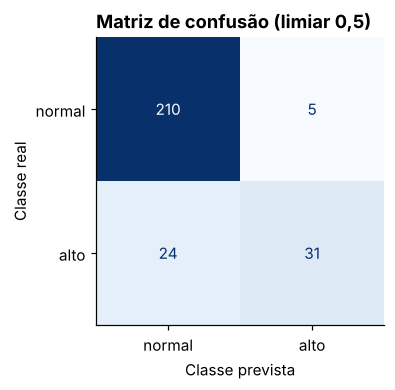

Exatidão: 0.89 (responder sempre «normal» daria 0.80)
Precisão: 0.86 | sensibilidade: 0.56


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score

alto = (lotes["rendimento_pct"] >= 20).astype(int)
print(f"Lotes de rendimento alto: {alto.mean():.1%}")

Xc_treino, Xc_teste, yc_treino, yc_teste = train_test_split(lotes[medicoes], alto, test_size=0.3, random_state=42, stratify=alto)
classificador = Pipeline([("escala", StandardScaler()), ("modelo", LogisticRegression())]).fit(Xc_treino, yc_treino)
previsto = classificador.predict(Xc_teste)                           # limiar de 0,5

fig, ax = plt.subplots(figsize=(4.2, 3.4))
ConfusionMatrixDisplay(confusion_matrix(yc_teste, previsto), display_labels=["normal", "alto"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title("Matriz de confusão (limiar 0,5)")
plt.show()

print(f"Exatidão: {classificador.score(Xc_teste, yc_teste):.2f} (responder sempre «normal» daria {1 - yc_teste.mean():.2f})")
print(f"Precisão: {precision_score(yc_teste, previsto):.2f} | sensibilidade: {recall_score(yc_teste, previsto):.2f}")

As linhas da matriz são as classes reais e as colunas são as previstas. A diagonal tem os acertos. A exatidão tem de ser lida ao lado da linha de base: como só um lote em cada cinco é de rendimento alto, responder sempre «normal» já acerta em cerca de 80% dos casos.

**Para rever a fundo:** [Uma boa previsão não garante uma boa decisão](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_1_do_problema_a_decisao/03_Previsao_nao_e_Decisao.ipynb) · [Métricas de avaliação](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/01_Metricas_de_Avaliacao.ipynb) · [Regressão logística](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_5_modelos_lineares/03_Regressao_Logistica.ipynb)

### `Exercício 5` – Mexer no limiar

1. Obtém as probabilidades da classe «alto» com `predict_proba` e calcula a precisão e a sensibilidade para os limiares 0,3, 0,5 e 0,7.
2. O lagar paga o prémio **à chegada**, com base na previsão. Que erro lhe custa dinheiro, e que limiar faz mais sentido?
3. Noutro cenário, o lagar usa a previsão para encaminhar os lotes para uma linha de extração mais cuidada, que custa pouco. Que erro pesa mais agora?

In [11]:
# Escreve aqui o código do exercício 5

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
probabilidade = classificador.predict_proba(Xc_teste)[:, 1]
for limiar in [0.3, 0.5, 0.7]:
    p = (probabilidade >= limiar).astype(int)
    print(f"limiar {limiar}: precisão {precision_score(yc_teste, p):.2f} | sensibilidade {recall_score(yc_teste, p):.2f} | assinalados: {p.sum()}")
```

2. Se o prémio é pago à chegada, cada **falso positivo** é um prémio pago a um lote que não o merecia. Interessa uma precisão alta, logo um limiar mais alto, aceitando que alguns lotes bons fiquem sem prémio.
3. Se assinalar um lote custa pouco, o erro caro passa a ser o **falso negativo**: um lote bom tratado na linha normal. Interessa uma sensibilidade alta, logo um limiar mais baixo.

O mesmo modelo serve as duas decisões com limiares diferentes. Num projeto real, o limiar escolhe-se com dados de validação e não com o teste, que fica guardado para a avaliação final.

</details>

## Parte 5 – Sobreajuste e validação cruzada

Em resumo:

- Um modelo demasiado simples não capta o padrão: tem erro alto no treino e fora dele (**subajuste**). Um modelo demasiado flexível decora o ruído: tem erro baixo no treino e alto fora dele (**sobreajuste**).
- A flexibilidade é controlada por **hiperparâmetros**: valores que se escolhem antes de treinar, como a profundidade de uma árvore ou o número de vizinhos do KNN.
- Uma só divisão em treino e validação é um sorteio. Na **validação cruzada**, os dados de treino dividem-se em *k* partes e cada parte serve de validação uma vez. O resultado é a média.
- Os hiperparâmetros escolhem-se por validação cruzada no conjunto de treino. O conjunto de teste continua guardado.

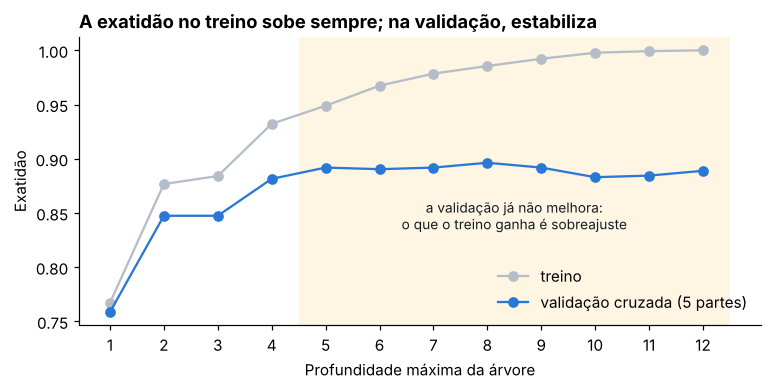

In [12]:
from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeClassifier

Xv_treino, Xv_teste, yv_treino, yv_teste = train_test_split(lotes[medicoes], lotes["variedade"], test_size=0.25,
                                                            random_state=42, stratify=lotes["variedade"])
profundidades = np.arange(1, 13)
no_treino, na_validacao = validation_curve(DecisionTreeClassifier(random_state=0), Xv_treino, yv_treino,
                                           param_name="max_depth", param_range=profundidades, cv=5)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(profundidades, no_treino.mean(axis=1), "o-", color=CINZA, label="treino")
ax.plot(profundidades, na_validacao.mean(axis=1), "o-", color=AZUL, label="validação cruzada (5 partes)")
ax.axvspan(4.5, 12.5, color=AVISO, alpha=0.12, lw=0)
ax.text(8.5, 0.835, "a validação já não melhora:\no que o treino ganha é sobreajuste", ha="center", color=TINTA, fontsize=9)
ax.set_xlabel("Profundidade máxima da árvore")
ax.set_ylabel("Exatidão")
ax.set_xticks(profundidades)
ax.set_title("A exatidão no treino sobe sempre; na validação, estabiliza")
ax.legend(frameon=False, loc="lower right")
plt.show()

A curva de treino sobe até 1: uma árvore com profundidade suficiente acerta em todos os lotes que viu. A curva de validação sobe até à profundidade 5 e depois fica praticamente igual, à volta de 0,89. A partir daí, tudo o que a árvore ganha no treino é ruído decorado, e a distância entre as duas curvas é o sobreajuste. Entre modelos que validam de forma equivalente, escolhe-se o mais simples: aqui, a profundidade 5.

**Para rever a fundo:** [Sobreajuste, viés e variância](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/05_Sobreajuste_Vies_e_Variancia.ipynb) · [Validação cruzada](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/06_Validacao_Cruzada.ipynb)

### `Exercício 6` – Escolher *k* sem tocar no teste

Usa `Xv_treino` e `yv_treino`, só com as colunas da lista `frutos`, para escolher o número de vizinhos de um KNN.

1. Monta um `Pipeline` com `StandardScaler` e `KNeighborsClassifier`.
2. Para *k* = 1, 3, 5, …, 31, calcula a exatidão média com validação cruzada de 5 partes.
3. Treina o melhor modelo em todo o treino e avalia-o, uma vez, em `Xv_teste[frutos]`.

In [13]:
# Escreve aqui o código do exercício 6

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.neighbors import KNeighborsClassifier

valores = range(1, 32, 2)
medias = []
for k in valores:
    knn = Pipeline([("escala", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    medias.append(cross_val_score(knn, Xv_treino[frutos], yv_treino, cv=5).mean())

melhor_k = list(valores)[int(np.argmax(medias))]
final = Pipeline([("escala", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=melhor_k))]).fit(Xv_treino[frutos], yv_treino)
print(f"Melhor k: {melhor_k} (validação cruzada: {max(medias):.3f}) | teste: {final.score(Xv_teste[frutos], yv_teste):.3f}")
```

O melhor valor é *k* = 3, mas olha para a lista `medias` antes de tirar conclusões: entre *k* = 1 e *k* = 15 a exatidão quase não muda (de 0,93 a 0,94), e só com valores maiores começa a descer devagar, porque o modelo alisa de mais. As diferenças entre valores próximos são menores do que a variação de uma parte para outra, por isso não vale a pena discutir a terceira casa decimal. Nestes dados as variedades separam-se bem e o KNN é pouco sensível a *k*; noutros problemas, a curva tem um máximo mais marcado. O `GridSearchCV` faz esta procura numa só instrução, e vamos usá-lo a partir do módulo 6.

</details>

## Onde rever cada assunto

| Parte | Assunto | Capítulos do tutorial de ciência de dados |
| --- | --- | --- |
| 1 | Modelo, atributos, alvo | módulo 4, capítulo 1 |
| 2 | Treino, teste, linha de base | módulo 4, capítulo 2 |
| 3 | Escalas, codificação, fugas, *pipelines* | módulo 4, capítulos 3 a 6 |
| 4 | Métricas e limiar | módulo 1, capítulo 3; módulo 6, capítulo 1 |
| 5 | Sobreajuste e validação cruzada | módulo 6, capítulos 5 e 6 |

## Verifica o que aprendeste

- [ ] Sei dizer o que são atributos, alvo, treinar e prever, e distinguir regressão de classificação.
- [ ] Sei porque o erro de treino é otimista e para que serve o conjunto de teste.
- [ ] Sei calcular uma linha de base e explicar porque é necessária.
- [ ] Sei identificar uma fuga de informação e evitá-la com um `Pipeline`.
- [ ] Sei ler uma matriz de confusão e calcular a precisão e a sensibilidade.
- [ ] Sei explicar o efeito de mudar o limiar e relacioná-lo com o custo dos erros.
- [ ] Sei reconhecer o sobreajuste numa curva de treino e validação.
- [ ] Sei escolher um hiperparâmetro com validação cruzada, sem usar o teste.

## Leitura recomendada

- https://scikit-learn.org/stable/getting_started.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://scikit-learn.org/stable/modules/cross_validation.html